# Leche cruda y temperatura de Rafaela

**Qué es.** Las Partes III y IV usan la temperatura dentro de un modelo: el ciclo anual de la proteína y la grasa, y
la probabilidad de superar los umbrales de calidad. Esta parte mira la relación directamente, antes de modelar: a cada
medición de leche cruda se le suma la temperatura de Rafaela **del mismo día** y se pregunta cuánto se parecen, si
la relación es lineal, si sobrevive al calendario y con qué ventana de días responde la leche.

**Las preguntas, en orden.**
1. Cada parámetro de la leche cruda y la temperatura en el tiempo, con el mismo eje.
2. Grasa, proteína y sólidos totales contra la temperatura: rectas por mínimos cuadrados, por industria-día.
3. ¿Es lineal? ¿Mejora al promediar la temperatura de varios días? ¿Sobrevive al restar el mes (anomalías)?
4. ¿La leche se parece más a la temperatura de la semana anterior? (desfase de una semana)
5. Células somáticas (RCS) y recuento bacteriano (RBT) contra la temperatura, con el umbral de la Parte IV.

**Datos.**
- **Leche cruda**: `../datos/leche_cruda.csv` (`R.LECHE_CRUDA`; las industrias ya van como `IND-nn`). `fecha`
  es la del informe y `fecha_origen` dice de dónde salió: `nombre` y `contenido` son la fecha escrita en el
  archivo; `creación` es la fecha de creación del archivo, que coincide con la real dentro de ±3 días en el
  89% de los casos.
- **Temperatura**: `datos_entrada/temperatura_rafaela.csv` (`R.TEMPERATURA`), NASA POWER diaria (`t_media` es
  T2M, la media de 24 h; validada contra la estación SMN Rafaela, r = 0,98).
  Las precipitaciones quedan fuera de este cuaderno: a diferencia de la temperatura, la serie de NASA POWER no se
  validó contra el SMN.
- **Recuentos**: células somáticas (RCS) y recuento bacteriano (RBT) se corrigen con las mismas reglas que la
  regresión logística (`src/logistica_leche.py`): el RBT de IND-59 desde mayo de 2024 viene en otra unidad y se
  descarta, y unos pocos RCS redondos de esa industria, que parecen un RBT mal ubicado, también.
- **Confidencialidad**: `archivo` (el nombre del archivo del informe) es texto libre. Se reemplaza al cargar por
  `informe`, un identificador (`INF-nnnnn`) numerado por (cliente, fecha, archivo), y la columna se descarta.
- **Salida**: gráficos en `resultados/temperatura_leche_cruda/`.

In [1]:
import sys
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))

import time
import numpy as np
import pandas as pd
from IPython.display import display

import datos_entrenamiento as DE
import logistica_leche as L
import rutas as R

inicio = time.time()
RAIZ = R.RAIZ
SALIDA_DIR = R.RESULTADOS / "temperatura_leche_cruda"
SALIDA_DIR.mkdir(parents=True, exist_ok=True)

leche = pd.read_csv(R.LECHE_CRUDA, encoding="utf-8-sig", low_memory=False, parse_dates=["fecha"])
temp = pd.read_csv(R.TEMPERATURA, encoding="utf-8-sig", parse_dates=["fecha"])
N_ARCHIVO = len(leche)

# `archivo` es texto libre: se reemplaza por un identificador del informe y se descarta
# (numerado por cliente, fecha y archivo; el mismo nombre de archivo aparece en varios clientes)
orden = leche[["cliente", "fecha", "archivo"]].drop_duplicates().sort_values(["cliente", "fecha", "archivo"])
informe = pd.Series([f"INF-{i:05d}" for i in range(1, len(orden) + 1)], index=pd.MultiIndex.from_frame(orden))
leche.insert(1, "informe", informe.reindex(pd.MultiIndex.from_frame(leche[["cliente", "fecha", "archivo"]])).to_numpy())
leche = leche.drop(columns="archivo")
assert leche["informe"].notna().all() and "archivo" not in leche.columns
print(f"informes: {leche['informe'].nunique():,} · industrias: {leche['cliente'].nunique()}")

# Recuentos: las mismas reglas que L.cargar_leche (la regresión logística, Parte IV)
c = L.CAMBIO_UNIDAD_RBT
de_ind = leche["cliente"] == c["cliente"]
en_ufc = de_ind & (leche["fecha"] >= c["desde"]) & (leche["rbt"] >= c["minimo_en_ufc"])
tras = de_ind & (leche["fecha"] >= c["descartar_desde"])
raros = (de_ind & (leche["fecha"] >= pd.Timestamp("2024-06-01"))
         & (leche["celulas_somaticas"] >= 2000) & (leche["celulas_somaticas"] % 1000 == 0))
print(f"RBT descartados de {c['cliente']}: {int(((en_ufc | tras) & leche['rbt'].notna()).sum())} "
      f"(en UFC/mL: {int(en_ufc.sum())}) · RCS descartados: {int(raros.sum())}")
leche.loc[en_ufc | tras, "rbt"] = np.nan
leche.loc[raros, "celulas_somaticas"] = np.nan

print("leche cruda:", leche.shape, "|", leche["fecha"].min().date(), "->", leche["fecha"].max().date(),
      "| fechas nulas:", int(leche["fecha"].isna().sum()))
print("temperatura:", temp.shape, "|", temp["fecha"].min().date(), "->", temp["fecha"].max().date())
dias = pd.date_range(temp["fecha"].min(), temp["fecha"].max())
print("días faltantes en la serie:", len(dias) - temp["fecha"].nunique(),
      "| días sin valor:", temp.loc[temp["t_media"].isna(), "fecha"].dt.date.tolist())
assert temp["fecha"].is_unique

informes: 21,117 · industrias: 10
RBT descartados de IND-59: 21215 (en UFC/mL: 21093) · RCS descartados: 6
leche cruda: (628035, 22) | 2015-09-22 -> 2026-09-07 | fechas nulas: 0
temperatura: (4307, 4) | 2015-01-01 -> 2026-10-16
días faltantes en la serie: 0 | días sin valor: [datetime.date(2026, 10, 13), datetime.date(2026, 10, 14), datetime.date(2026, 10, 15), datetime.date(2026, 10, 16)]


## Unión por fecha

La fecha de la leche cruda es solo día (sin hora), igual que la de la temperatura, así que la unión es exacta
por día. Se verifica que no se duplique ninguna medición.

In [2]:
assert (leche["fecha"] == leche["fecha"].dt.normalize()).all()
cruce = leche.merge(temp[["fecha", "t_media", "t_max", "t_min"]], on="fecha", how="left", validate="many_to_one")
assert len(cruce) == len(leche)

con_t = cruce["t_media"].notna()
print(f"mediciones con temperatura: {int(con_t.sum()):,} de {len(cruce):,} ({100 * con_t.mean():.1f}%)")
sin_t = cruce.loc[~con_t, "fecha"]
fuera = pd.cut(sin_t, [pd.Timestamp.min, temp["fecha"].min() - pd.Timedelta(days=1), temp["fecha"].max(), pd.Timestamp.max],
               labels=["antes de la serie", "dentro (día sin valor)", "después de la serie"])
print("sin temperatura, por motivo:")
print(fuera.value_counts().to_string())
print("\nsin temperatura, por año:")
print(sin_t.dt.year.value_counts().sort_index().to_string())

mediciones con temperatura: 628,035 de 628,035 (100.0%)
sin temperatura, por motivo:
fecha
antes de la serie         0
dentro (día sin valor)    0
después de la serie       0

sin temperatura, por año:
Series([], )


In [3]:
# cobertura por industria y por origen de la fecha
comp = ["grasa", "proteina", "lactosa", "solidos_totales", "celulas_somaticas", "crioscopia"]
cruce["con_composicion"] = cruce[comp].notna().any(axis=1)
por_ind = cruce.groupby("cliente").agg(
    mediciones=("fecha", "size"),
    con_temperatura=("t_media", lambda s: int(s.notna().sum())),
    con_composicion_y_temperatura=("t_media", lambda s: int((s.notna() & cruce.loc[s.index, "con_composicion"]).sum())),
    desde=("fecha", "min"), hasta=("fecha", "max"))
por_ind["desde"], por_ind["hasta"] = por_ind["desde"].dt.date, por_ind["hasta"].dt.date
print(por_ind.to_string())
print()
print(cruce.groupby("fecha_origen")["t_media"].agg(mediciones="size", con_temperatura="count").to_string())

         mediciones  con_temperatura  con_composicion_y_temperatura       desde       hasta
cliente                                                                                    
IND-103         768              768                            748  2021-12-06  2026-09-04
IND-29        53423            53423                          46772  2019-09-05  2026-08-28
IND-30        17135            17135                          16942  2019-09-09  2026-09-02
IND-51         5363             5363                           2589  2024-09-15  2026-09-03
IND-57        35121            35121                          30239  2019-09-05  2026-09-03
IND-59        85771            85771                          54150  2019-09-09  2026-09-04
IND-68       156065           156065                         148803  2019-09-06  2026-09-07
IND-81       181799           181799                         178648  2015-09-22  2026-09-04
IND-88        82642            82642                          77284  2019-09-06 

In [4]:
# control: la temperatura asignada es la del día, sin desplazamientos
muestra = cruce[con_t].sample(2000, random_state=L.SEMILLA)
ref = temp.set_index("fecha")
assert (muestra["t_media"].to_numpy() == ref.loc[muestra["fecha"], "t_media"].to_numpy()).all()
print(cruce[con_t][["t_media", "t_max", "t_min"]].describe().round(2).to_string())

         t_media      t_max      t_min
count  628035.00  628035.00  628035.00
mean       19.71      27.02      13.32
std         6.71       7.21       6.31
min         2.46       8.78      -3.54
25%        14.37      21.52       8.39
50%        20.27      27.29      13.83
75%        25.00      32.44      18.09
max        35.31      45.02      29.61


## Gráficos: cada parámetro y la temperatura en el tiempo

Un gráfico por parámetro común de la leche cruda (los que informan las diez industrias) y uno de la
temperatura, todos con **el mismo eje de tiempo** para poder ponerlos uno al lado del otro. Al final, un
panel con todos apilados.

- **Cómo se resume.** Las industrias entran y salen de la serie en distintos momentos y tienen niveles
  distintos; un promedio crudo de todas las mediciones mezclaría ese cambio de composición con el de la
  leche. Por eso primero se toma la mediana de cada industria en cada día, y después, por semana, la
  mediana de esos valores (línea) y su rango intercuartil (banda: el 50% central de las industrias-día).
- **Período**: desde septiembre de 2019, cuando arrancan las industrias de forma continua (antes hay
  mediciones sueltas: la celda imprime cuántas). La temperatura cubre todo el período (desde 2015).
- **Escala logarítmica** en células somáticas y recuento bacteriano, que son muy asimétricos.
- Una semana con menos de 3 industrias con dato no se dibuja (queda un hueco).
- La urea total no se grafica: es `mun × 2,144`. Agua agregada y PAL tienen pocas mediciones.
- **Ojo con dos escalones** que no son estacionales y aparecen en todas las industrias a la vez (no es
  que cambie el grupo de industrias): el **punto crioscópico** sube unos 0,006 °C a mediados de 2024 en
  8 de las 10 industrias, y el **MUN** tiene saltos bruscos (2020-T2, 2021-T3, 2025-T2), con tramos
  casi planos e iguales entre industrias en 2025. Parecen cambios de calibración o de método del equipo,
  no de la leche: hay que confirmarlo antes de usarlos para modelar.
- En el recuento bacteriano ya no entra el RBT de IND-59 desde mayo de 2024, que está en otra unidad (valores mil
  veces más altos). Con esos valores la línea casi no cambiaba, porque la mediana entre industrias los amortigua,
  pero la banda se ensanchaba desde mediados de 2024.
- Los PNG quedan en `resultados/temperatura_leche_cruda/`.

In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import LogLocator, FuncFormatter

GRAFICOS = SALIDA_DIR

# paleta de referencia (modo claro): leche en azul, temperatura en naranja; texto y grilla neutros
SUPERFICIE, TEXTO, TEXTO_2, GRILLA = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
AZUL, NARANJA = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "text.color": TEXTO, "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

PARAMETROS = {   # columna: (título, unidad, escala log)
    "grasa": ("Grasa", "g/100 g", False),
    "proteina": ("Proteína", "g/100 g", False),
    "lactosa": ("Lactosa", "g/100 g", False),
    "solidos_totales": ("Sólidos totales", "g/100 g", False),
    "solidos_no_grasos": ("Sólidos no grasos", "g/100 g", False),
    "crioscopia": ("Punto crioscópico", "°C", False),
    "celulas_somaticas": ("Células somáticas", "miles/mL", True),
    "rbt": ("Recuento bacteriano total", "miles UFC/mL", True),
    "mun": ("Nitrógeno ureico (MUN)", "mg/dL", False),
}
DESDE, HASTA = pd.Timestamp("2019-09-01"), cruce["fecha"].max()

print(f"mediciones antes de {DESDE:%Y-%m-%d}, fuera de los gráficos: {int((cruce['fecha'] < DESDE).sum())}")
base = cruce[(cruce["fecha"] >= DESDE)]
dia = base.groupby(["cliente", "fecha"])[list(PARAMETROS)].median()          # una fila por industria-día
dia = dia.reset_index()
semana = dia.groupby(pd.Grouper(key="fecha", freq="W-MON", label="left", closed="left"))
MIN_INDUSTRIAS = 3   # una semana con menos industrias no es representativa (p. ej. la última, incompleta)
resumen_sem = {}
for p in PARAMETROS:
    q = semana[p].quantile([0.25, 0.5, 0.75]).unstack()
    n_ind = dia[dia[p].notna()].groupby(pd.Grouper(key="fecha", freq="W-MON", label="left", closed="left"))["cliente"].nunique()
    pocas = n_ind.reindex(q.index).fillna(0) < MIN_INDUSTRIAS
    q[pocas] = float("nan")
    resumen_sem[p] = q
    print(f"{p:18s} semanas con datos: {int((~pocas).sum())} | descartadas por < {MIN_INDUSTRIAS} industrias: {int(pocas.sum())}"
          f" | industrias por semana (mediana): {int(n_ind.median())}")

t = temp[(temp["fecha"] >= DESDE)].set_index("fecha")
t_sem = t[["t_media", "t_max", "t_min"]].resample("W-MON", label="left", closed="left").mean()


def eje_tiempo(ax):
    ax.set_xlim(DESDE, HASTA)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))
    ax.grid(axis="x", which="minor", color=GRILLA, linewidth=0.4)
    ax.tick_params(axis="both", length=0)


def dibujar_parametro(ax, p, titulo=True):
    nombre, unidad, log = PARAMETROS[p]
    r = resumen_sem[p].dropna()
    ax.fill_between(r.index, r[0.25], r[0.75], color=AZUL, alpha=0.18, linewidth=0)
    ax.plot(r.index, r[0.5], color=AZUL, linewidth=1.6, solid_joinstyle="round", solid_capstyle="round")
    if log:
        ax.set_yscale("log")
        ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
        ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
    else:
        lo, hi = r[0.25].quantile(0.005), r[0.75].quantile(0.995)    # recorte robusto: semanas raras no aplastan la serie
        margen = (hi - lo) * 0.08
        ax.set_ylim(lo - margen, hi + margen)
    ax.set_ylabel(unidad)
    if titulo:
        ax.set_title(nombre)
    eje_tiempo(ax)


def dibujar_temperatura(ax, titulo=True):
    ax.fill_between(t_sem.index, t_sem["t_min"], t_sem["t_max"], color=NARANJA, alpha=0.18, linewidth=0)
    ax.plot(t.index, t["t_media"], color=NARANJA, linewidth=0.4, alpha=0.35)
    ax.plot(t_sem.index, t_sem["t_media"], color=NARANJA, linewidth=1.6, solid_joinstyle="round", solid_capstyle="round")
    ax.set_ylabel("°C")
    if titulo:
        ax.set_title("Temperatura en Rafaela")
    eje_tiempo(ax)

mediciones antes de 2019-09-01, fuera de los gráficos: 60


grasa              semanas con datos: 366 | descartadas por < 3 industrias: 1 | industrias por semana (mediana): 7
proteina           semanas con datos: 366 | descartadas por < 3 industrias: 1 | industrias por semana (mediana): 7
lactosa            semanas con datos: 366 | descartadas por < 3 industrias: 1 | industrias por semana (mediana): 7
solidos_totales    semanas con datos: 366 | descartadas por < 3 industrias: 1 | industrias por semana (mediana): 7
solidos_no_grasos  semanas con datos: 366 | descartadas por < 3 industrias: 1 | industrias por semana (mediana): 7
crioscopia         semanas con datos: 366 | descartadas por < 3 industrias: 1 | industrias por semana (mediana): 7
celulas_somaticas  semanas con datos: 366 | descartadas por < 3 industrias: 1 | industrias por semana (mediana): 7
rbt                semanas con datos: 366 | descartadas por < 3 industrias: 1 | industrias por semana (mediana): 7
mun                semanas con datos: 366 | descartadas por < 3 industrias: 1 | 

### Temperatura

Línea gruesa: media semanal de la temperatura media diaria (NASA POWER, T2M). Línea fina: el valor de
cada día. Banda: entre la mínima y la máxima diarias, promediadas por semana.

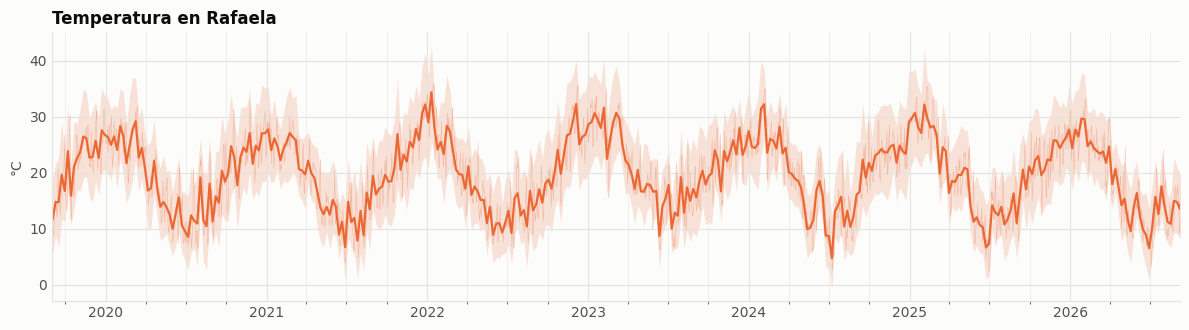

In [6]:
fig, ax = plt.subplots(figsize=(12, 3.4))
dibujar_temperatura(ax)
fig.tight_layout()
fig.savefig(GRAFICOS / "temperatura.png", dpi=150)
plt.show()

### Parámetros de la leche cruda

Línea: mediana semanal de las medianas por industria y día. Banda: rango intercuartil (el 50% central).

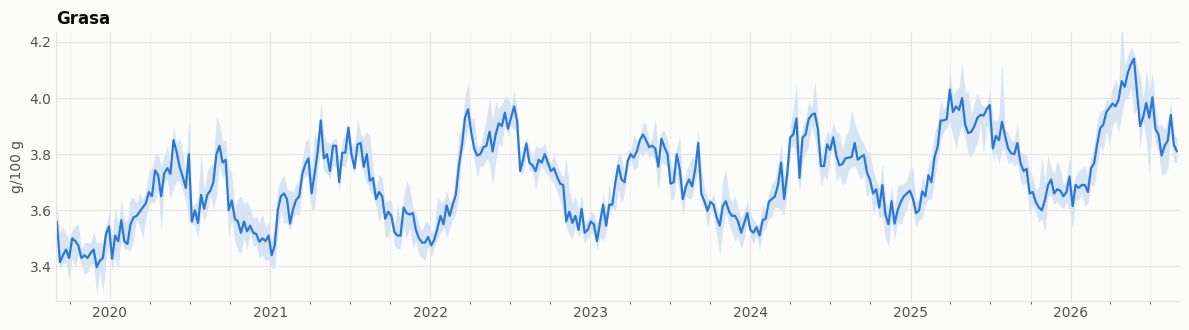

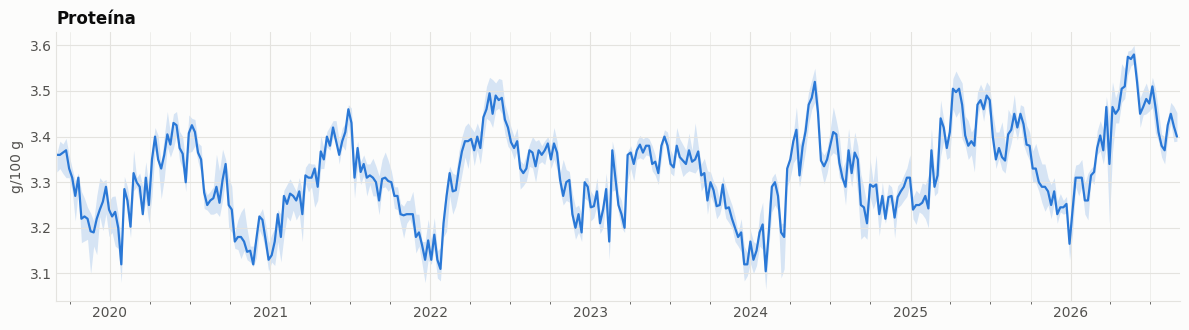

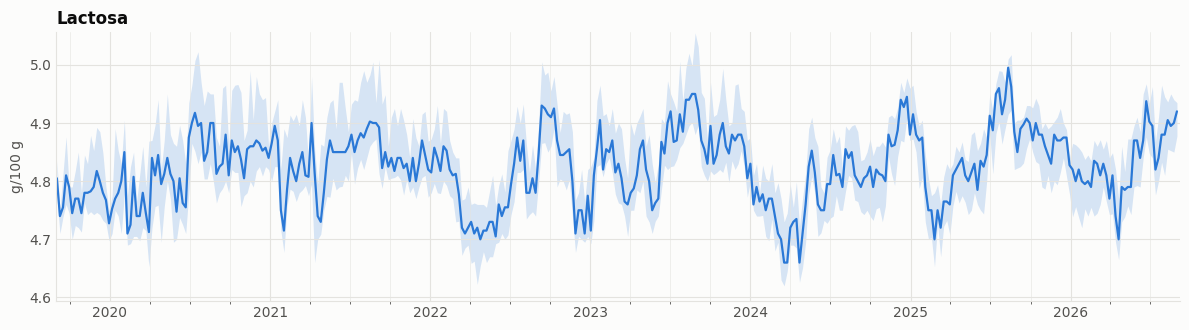

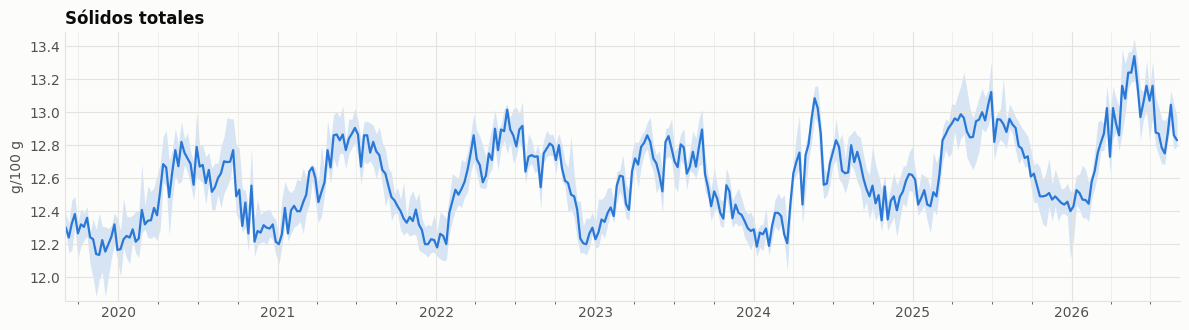

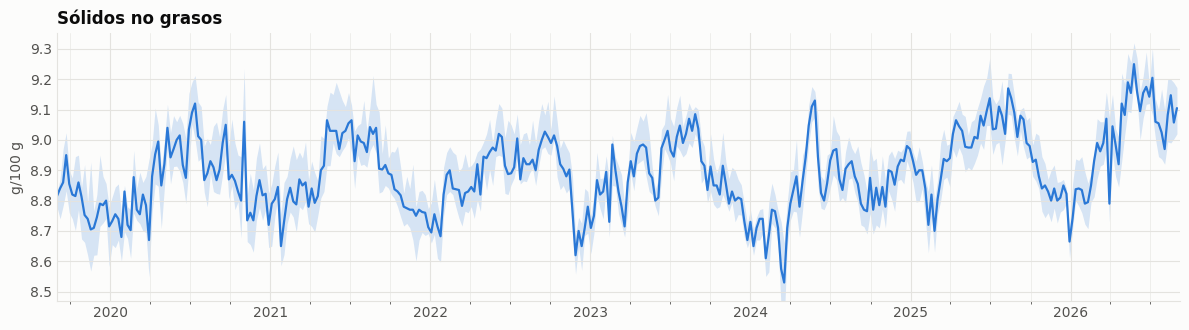

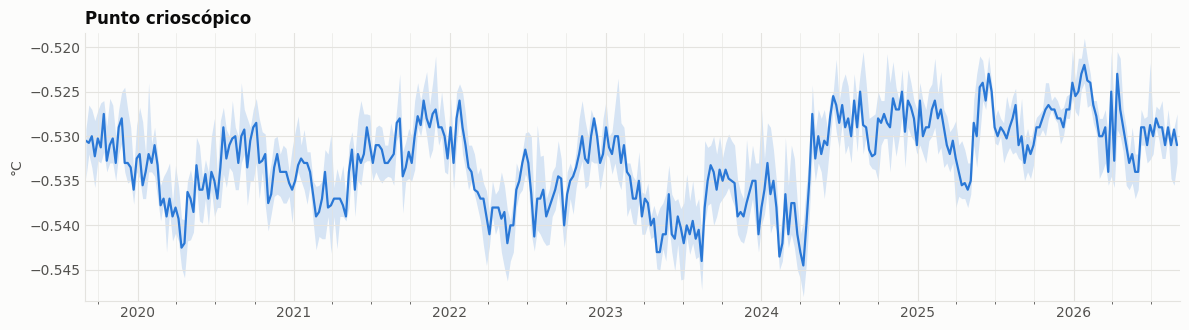

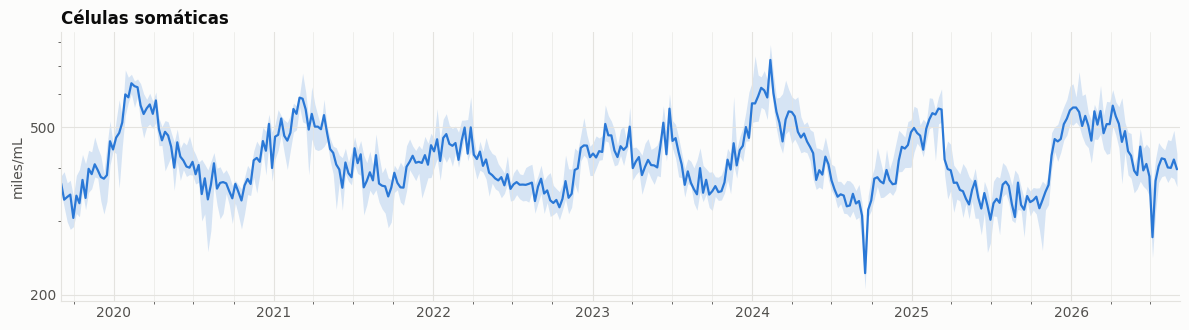

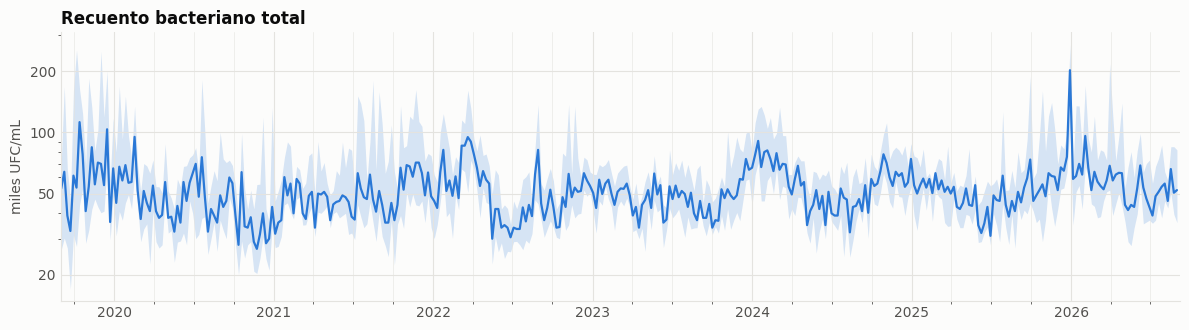

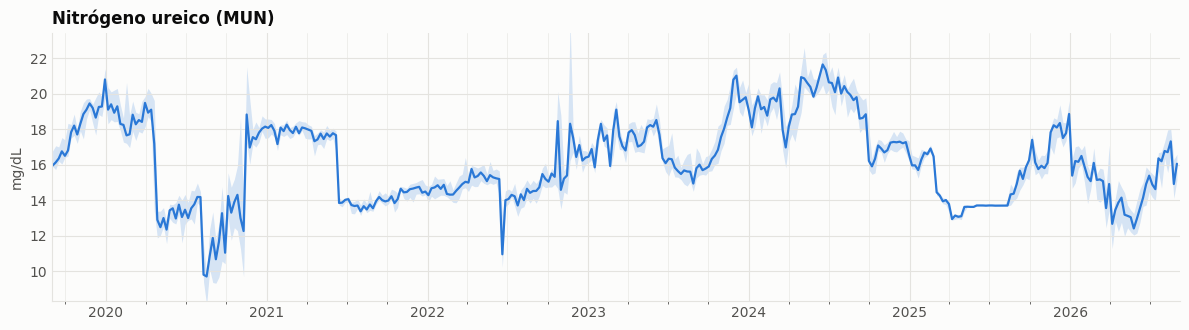

In [7]:
for p in PARAMETROS:
    fig, ax = plt.subplots(figsize=(12, 3.4))
    dibujar_parametro(ax, p)
    fig.tight_layout()
    fig.savefig(GRAFICOS / f"{p}.png", dpi=150)
    plt.show()

### Todo junto, para cruzar

Mismo eje de tiempo para todos los paneles y la temperatura arriba. Cada panel tiene su propia escala
vertical: lo que se compara es **cuándo** sube y baja cada serie, no su nivel.

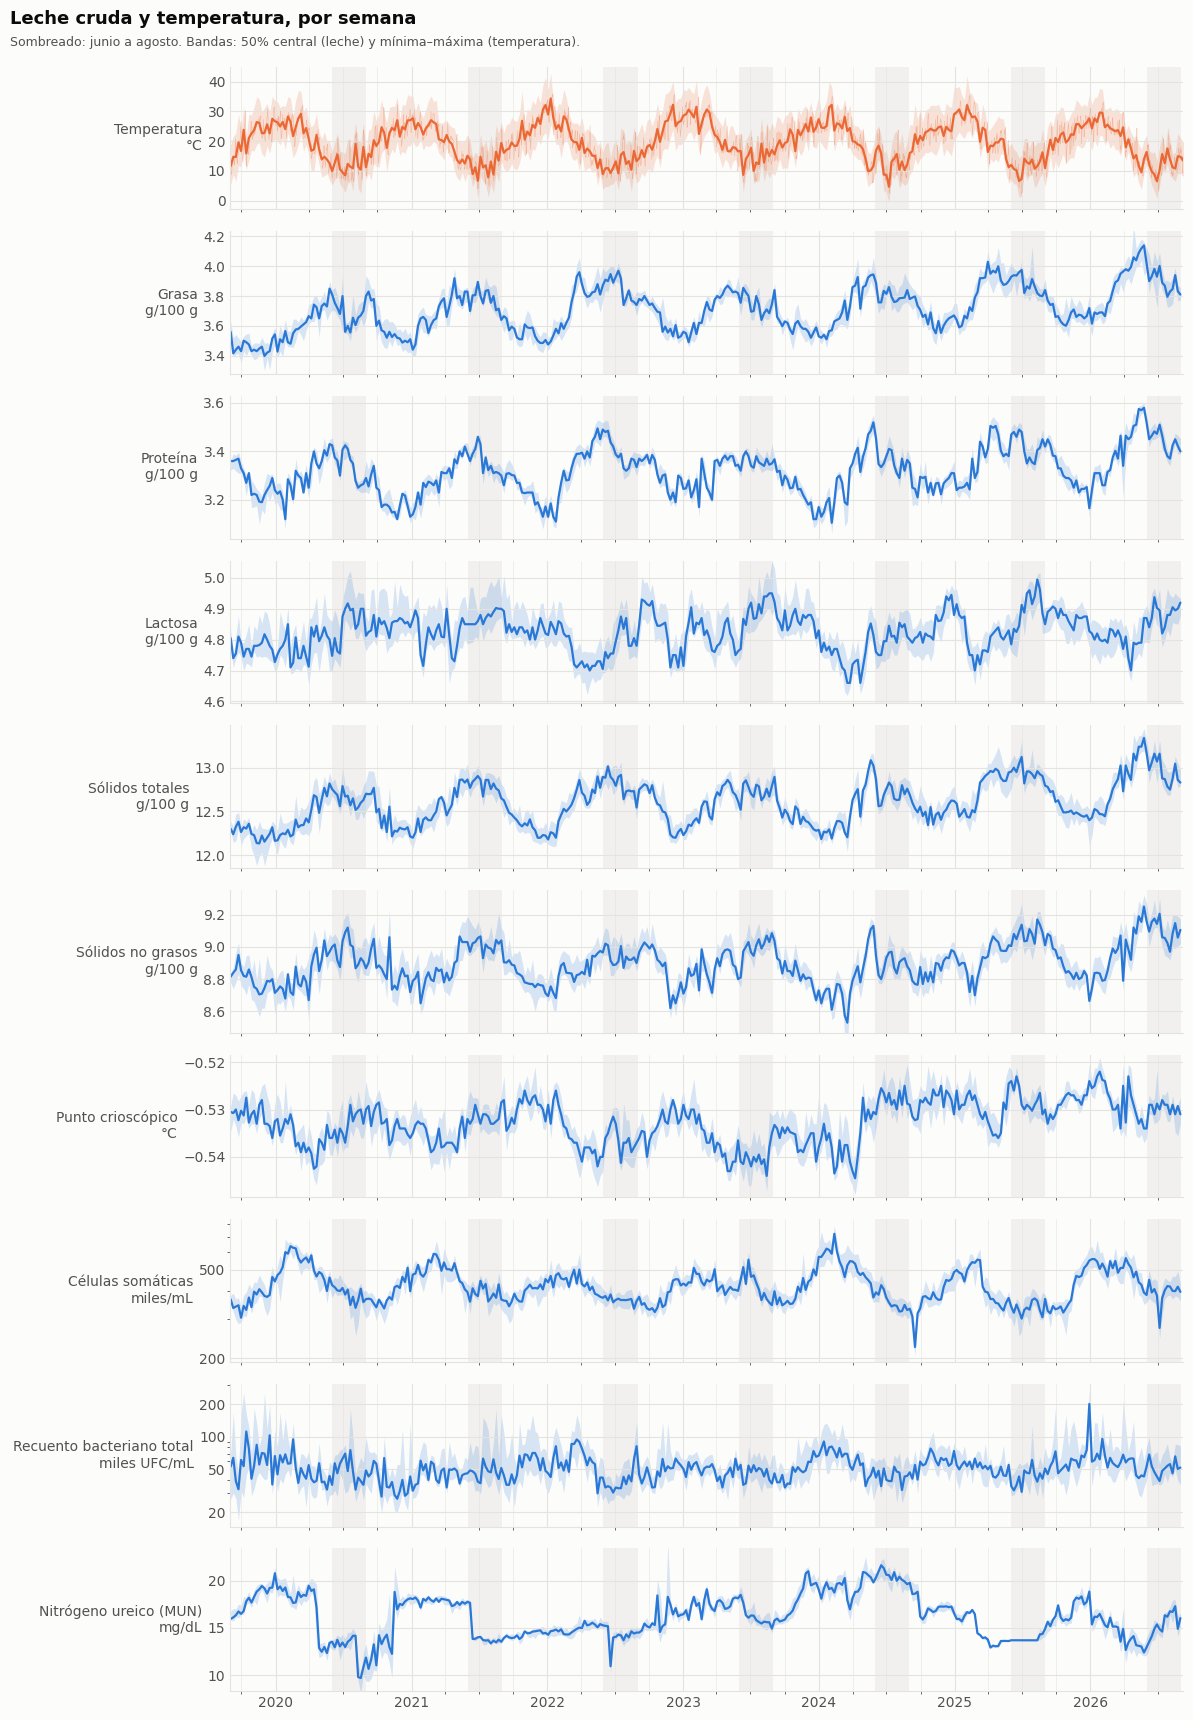

gráficos en resultados\temperatura_leche_cruda ['celulas_somaticas.png', 'correlacion_celulas_somaticas_temperatura.png', 'correlacion_grasa_temperatura.png', 'correlacion_grasa_temperatura_desfase_1semana.png', 'correlacion_proteina_temperatura.png', 'correlacion_proteina_temperatura_desfase_1semana.png', 'correlacion_rbt_temperatura.png', 'correlacion_solidos_totales_temperatura.png', 'correlacion_solidos_totales_temperatura_desfase_1semana.png', 'crioscopia.png', 'grasa.png', 'lactosa.png', 'linealidad_semanal_temperatura.png', 'mun.png', 'panel_leche_temperatura.png', 'proteina.png', 'rbt.png', 'solidos_no_grasos.png', 'solidos_totales.png', 'temperatura.png']


In [8]:
filas = 1 + len(PARAMETROS)
fig, axes = plt.subplots(filas, 1, figsize=(12, 1.75 * filas), sharex=True)
dibujar_temperatura(axes[0], titulo=False)
axes[0].set_ylabel("Temperatura\n°C", rotation=0, ha="right", va="center")
for ax, p in zip(axes[1:], PARAMETROS):
    dibujar_parametro(ax, p, titulo=False)
    nombre, unidad, _ = PARAMETROS[p]
    ax.set_ylabel(f"{nombre}\n{unidad}", rotation=0, ha="right", va="center")
# un sombreado suave en cada invierno (junio a agosto) ayuda a alinear la vista entre paneles
for ax in axes:
    for anio in range(DESDE.year, HASTA.year + 1):
        ax.axvspan(pd.Timestamp(anio, 6, 1), pd.Timestamp(anio, 9, 1), color=GRILLA, alpha=0.45, linewidth=0, zorder=0)
fig.suptitle("Leche cruda y temperatura, por semana", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.text(0.01, 0.985 - 0.2 / filas, "Sombreado: junio a agosto. Bandas: 50% central (leche) y mínima–máxima (temperatura).",
         ha="left", va="top", color=TEXTO_2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.975))
fig.savefig(GRAFICOS / "panel_leche_temperatura.png", dpi=150)
plt.show()
print("gráficos en", GRAFICOS.relative_to(RAIZ), sorted(f.name for f in GRAFICOS.glob("*.png")))

## Correlación lineal: grasa, proteína y sólidos totales contra la temperatura

Cada punto es una **industria-día**: la mediana de una industria en un día (la misma tabla `dia` de los
gráficos de arriba, desde septiembre de 2019) contra la temperatura media de Rafaela de ese día. Resumir
por industria-día evita que los días con muchas muestras de una sola industria dominen la nube.

- **Recta**: regresión lineal por mínimos cuadrados, `componente = a + b · temperatura`. La pendiente `b`
  es cuánto cambia el componente (g/100 g) por cada °C.
- **Pearson r** mide qué tan bien se ajustan los puntos a esa recta; **R² = r²** es la parte de la
  variación que la recta explica con la temperatura.
- **Por industria**: el mismo r dentro de cada industria. Si la relación aparece en todas, no es un efecto
  de qué industrias informan en cada época del año.
- Los sólidos totales son `grasa + sólidos no grasos`, y la proteína es la mayor parte variable de los no
  grasos: si la relación con la temperatura es lineal en los sólidos, tiene que verse en sus componentes.

industrias-día: 9,436 | industrias: 10
Grasa: grasa = 3.967 -0.0127 · temperatura (-0.13 g/100 g cada 10 °C) | r = -0.368 | R² = 0.136 | n = 7,818


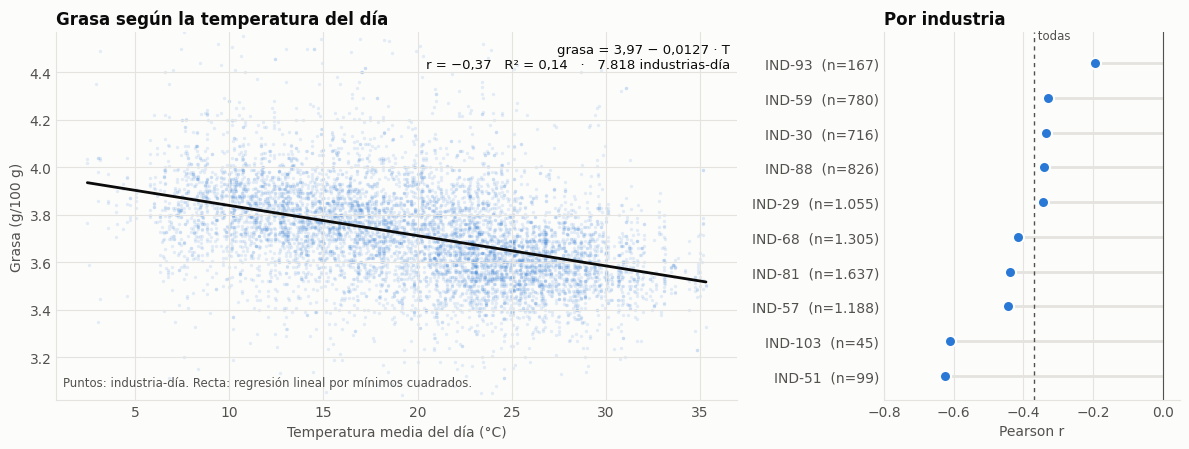

Proteína: proteína = 3.494 -0.0089 · temperatura (-0.09 g/100 g cada 10 °C) | r = -0.494 | R² = 0.244 | n = 7,821


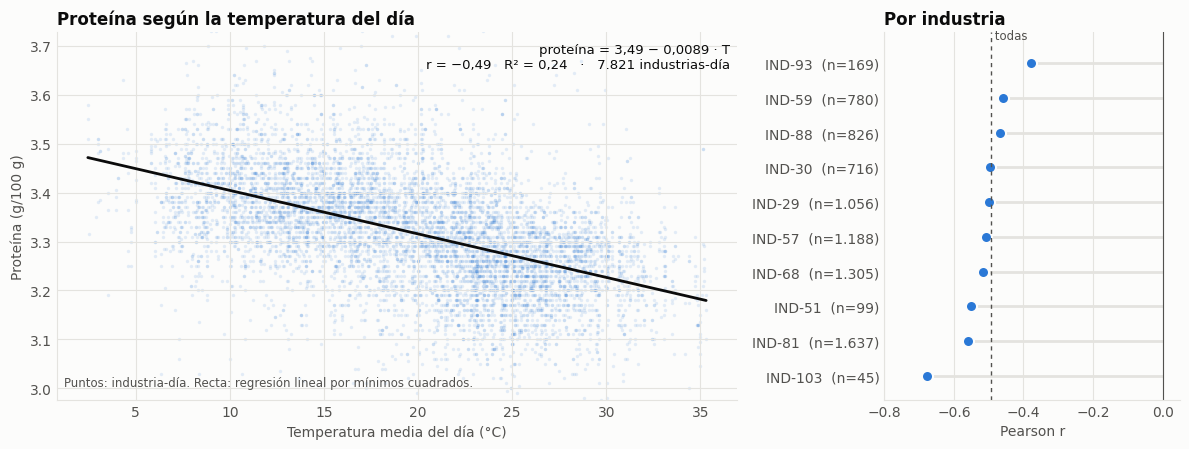

Sólidos totales: sólidos totales = 13.094 -0.0246 · temperatura (-0.25 g/100 g cada 10 °C) | r = -0.445 | R² = 0.198 | n = 7,822


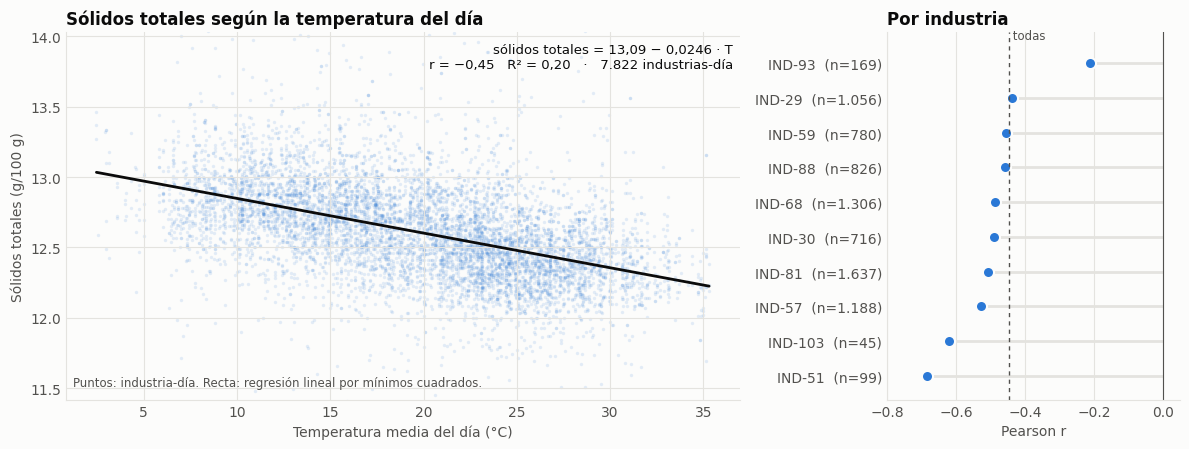


r por industria:
         grasa  proteina  solidos_totales
cliente                                  
IND-103 -0.611    -0.678           -0.619
IND-29  -0.344    -0.499           -0.438
IND-30  -0.335    -0.496           -0.490
IND-51  -0.626    -0.549           -0.683
IND-57  -0.445    -0.508           -0.526
IND-59  -0.330    -0.459           -0.456
IND-68  -0.414    -0.517           -0.487
IND-81  -0.439    -0.558           -0.506
IND-88  -0.340    -0.468           -0.458
IND-93  -0.193    -0.378           -0.212


In [9]:
import numpy as np

COMPONENTES = ["grasa", "proteina", "solidos_totales"]
dec = lambda v, d: f"{v:.{d}f}".replace("-", "−").replace(".", ",")      # coma decimal

RECUENTOS = ["celulas_somaticas", "rbt"]      # sección final: escala logarítmica
corr = dia[["cliente", "fecha"] + COMPONENTES + ["solidos_no_grasos", "lactosa"] + RECUENTOS].merge(
    temp[["fecha", "t_media"]], on="fecha", how="left", validate="many_to_one")
corr = corr.dropna(subset=["t_media"])
print(f"industrias-día: {len(corr):,} | industrias: {corr['cliente'].nunique()}")


def recta(g, p, x="t_media"):
    g = g.dropna(subset=[p, x])
    b, a = np.polyfit(g[x], g[p], 1)
    return a, b, g[p].corr(g[x]), len(g)


def figura_correlacion(p, x="t_media", eje_x="Temperatura media del día (°C)",
                       titulo="según la temperatura del día", archivo=None, umbral=None):
    # Con escala log (recuentos), la recta y el r se calculan sobre log10 del valor: la pendiente es un factor
    # multiplicativo por °C. `umbral` dibuja una línea horizontal (el corte de la regresión logística).
    nombre, unidad, log = PARAMETROS[p]
    col = p
    if log:
        col = f"log10_{p}"
        corr[col] = np.log10(corr[p].where(corr[p] > 0))
    a, b, r, n = recta(corr, col, x)
    if log:
        print(f"{nombre}: log10 = {a:.3f} {b:+.4f} · temperatura (×{10 ** (10 * b):.2f} cada 10 °C, "
              f"{100 * (10 ** (10 * b) - 1):+.0f} %) | r = {r:.3f} | R² = {r ** 2:.3f} | n = {n:,}")
    else:
        print(f"{nombre}: {nombre.lower()} = {a:.3f} {b:+.4f} · temperatura ({10 * b:+.2f} g/100 g cada 10 °C)"
              f" | r = {r:.3f} | R² = {r ** 2:.3f} | n = {n:,}")
    por_ind = (corr.groupby("cliente")
               .apply(lambda g: pd.Series(dict(zip(["a", "pendiente", "r", "n"], recta(g, col, x)))), include_groups=False)
               .drop(columns="a").sort_values("r"))
    por_ind["n"] = por_ind["n"].astype(int)

    fig, (ax, ax_ind) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [2.3, 1]})
    d = corr.dropna(subset=[col, x])
    ax.scatter(d[x], d[col], s=6, color=AZUL, alpha=0.12, linewidths=0, rasterized=True)
    xr = np.array([d[x].min(), d[x].max()])
    ax.plot(xr, a + b * xr, color=TEXTO, linewidth=2, solid_capstyle="round")
    lo, hi = d[col].quantile([0.005, 0.995])     # recorte robusto: unos pocos días raros no aplastan la nube
    margen = (hi - lo) * 0.05
    ax.set_ylim(lo - margen, hi + margen)
    ax.set_xlabel(eje_x)
    ax.set_title(f"{nombre} {titulo}")
    signo = "−" if b < 0 else "+"
    if log:
        # eje en log10 con rótulos en la unidad original (1-2-5 por década)
        marcas = [m * 10 ** e for e in range(-1, 6) for m in (1, 2, 5)]
        marcas = [m for m in marcas if lo - margen <= np.log10(m) <= hi + margen]
        ax.set_yticks(np.log10(marcas), [f"{m:,.0f}".replace(",", ".") if m >= 1 else f"{m:g}".replace(".", ",")
                                         for m in marcas])
        ax.set_ylabel(f"{nombre} ({unidad}, escala log)")
        if umbral is not None:
            ax.axhline(np.log10(umbral), color=NARANJA, linewidth=1.2, linestyle=(0, (4, 3)))
            ax.text(xr[0], np.log10(umbral), f" umbral de la Parte IV: {umbral:,.0f}".replace(",", "."),
                    color=NARANJA, fontsize=8.5, va="bottom")
        factor = 10 ** (10 * b)
        ecuacion = (f"log₁₀ = {dec(a, 2)} {signo} {dec(abs(b), 4)} · T   (×{dec(factor, 2)} cada 10 °C)")
    else:
        ax.set_ylabel(f"{nombre} ({unidad})")
        ecuacion = f"{nombre.lower()} = {dec(a, 2)} {signo} {dec(abs(b), 4)} · T"
    ax.text(0.99, 0.97, f"{ecuacion}\n"
            f"r = {dec(r, 2)}   R² = {dec(r ** 2, 2)}   ·   {n:_} industrias-día".replace("_", "."),
            transform=ax.transAxes, ha="right", va="top", color=TEXTO, fontsize=9.5)
    ax.text(0.01, 0.03, "Puntos: industria-día. Recta: regresión lineal por mínimos cuadrados"
            + (" sobre log₁₀." if log else "."),
            transform=ax.transAxes, ha="left", va="bottom", color=TEXTO_2, fontsize=8.5)
    ax.tick_params(axis="both", length=0)

    y = range(len(por_ind))
    ax_ind.hlines(y, 0, por_ind["r"], color=GRILLA, linewidth=2)
    ax_ind.plot(por_ind["r"], y, "o", color=AZUL, markersize=8, markeredgecolor=SUPERFICIE, markeredgewidth=1.5)
    ax_ind.axvline(r, color=TEXTO_2, linewidth=1, linestyle=(0, (3, 3)))
    ax_ind.text(r, len(por_ind) - 0.4, " todas", color=TEXTO_2, fontsize=8.5, va="bottom")
    ax_ind.axvline(0, color=TEXTO_2, linewidth=0.8)
    ax_ind.set_yticks(list(y), [f"{c}  (n={k:,})".replace(",", ".") for c, k in por_ind["n"].items()])
    ax_ind.set_ylim(-0.7, len(por_ind) - 0.1)
    ax_ind.set_xlim(min(-0.8 if not log else -0.05, por_ind["r"].min() - 0.05),
                    max(0.05 if not log else 0.8, por_ind["r"].max() + 0.05))
    ax_ind.set_xlabel("Pearson r")
    ax_ind.set_title("Por industria")
    ax_ind.grid(axis="y", visible=False)
    ax_ind.tick_params(axis="both", length=0)
    fig.tight_layout()
    fig.savefig(GRAFICOS / (archivo or f"correlacion_{p}_temperatura.png"), dpi=150)
    plt.show()
    return por_ind


por_industria = {}
for p in COMPONENTES:
    por_industria[p] = figura_correlacion(p)
print()
print("r por industria:")
print(pd.DataFrame({p: por_industria[p]["r"] for p in COMPONENTES}).round(3).to_string())

### ¿Es lineal? Y ¿mejora al promediar la temperatura?

Tres pruebas, las mismas para los tres componentes (más sólidos no grasos y lactosa como referencia):

1. **Curvatura.** Se ajusta también `a + b·T + c·T²`. Si el R² cuadrático no supera al lineal, una recta
   alcanza: la relación es lineal en el rango de temperaturas de Rafaela.
2. **Medias por tramo de temperatura** (tramos de 2 °C). Si caen sobre la recta, no hay un umbral ni una
   meseta escondidos en la nube.
3. **Ventana de temperatura.** La vaca no responde a la temperatura de un día aislado: se prueba la media
   de los últimos 7, 15, 30, 60 y 90 días, y además la serie semanal (mediana entre industrias-día, como
   en los gráficos), que promedia el ruido de día a día. Si el r sube, la relación es más lineal de lo que
   muestra la nube diaria.

In [10]:
REFERENCIA = COMPONENTES + ["solidos_no_grasos", "lactosa"]
VENTANAS = [1, 7, 15, 30, 60, 90]
serie_t = temp.set_index("fecha")["t_media"].sort_index()
for w in VENTANAS:
    corr[f"t{w}"] = corr["fecha"].map(serie_t.rolling(f"{w}D").mean())

g_sem = pd.Grouper(key="fecha", freq="W-MON", label="left", closed="left")
sem = corr.groupby(g_sem).agg({**{p: "median" for p in REFERENCIA}, **{f"t{w}": "mean" for w in VENTANAS}})
sem = sem[corr.groupby(g_sem)["cliente"].nunique() >= MIN_INDUSTRIAS].dropna()


def r2(x, y, grado):
    coef = np.polyfit(x, y, grado)
    resid = y - np.polyval(coef, x)
    return 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum()


filas = []
for p in REFERENCIA:
    for nivel, tabla in [("industria-día", corr), ("semana", sem)]:
        for w in VENTANAS:
            d = tabla[[p, f"t{w}"]].dropna()
            x, y = d[f"t{w}"].to_numpy(), d[p].to_numpy()
            filas.append({"componente": p, "nivel": nivel, "ventana_días": w, "n": len(d),
                          "r": np.corrcoef(x, y)[0, 1], "R²_lineal": r2(x, y, 1), "R²_cuadrático": r2(x, y, 2)})
lin = pd.DataFrame(filas)
lin["ganancia_cuadrática"] = lin["R²_cuadrático"] - lin["R²_lineal"]
pd.set_option("display.width", 160)
for nivel in ["industria-día", "semana"]:
    print(f"--- r de Pearson por ventana de temperatura · nivel {nivel}")
    print(lin[lin.nivel == nivel].pivot(index="componente", columns="ventana_días", values="r").loc[REFERENCIA].round(3).to_string())
    print()
print("--- curvatura: lo que agrega el término T² al R² (máximo sobre ventanas y niveles)")
print(lin.groupby("componente")["ganancia_cuadrática"].max().loc[REFERENCIA].round(4).to_string())
mejor = lin[lin.nivel == "semana"].loc[lambda t: t.groupby("componente")["r"].idxmin()].set_index("componente").loc[REFERENCIA]
print()
print("--- mejor ventana a nivel semanal")
print(mejor[["ventana_días", "n", "r", "R²_lineal", "R²_cuadrático"]].round(3).to_string())

--- r de Pearson por ventana de temperatura · nivel industria-día
ventana_días          1      7      15     30     60     90
componente                                                 
grasa             -0.368 -0.389 -0.368 -0.319 -0.211 -0.090
proteina          -0.494 -0.582 -0.557 -0.490 -0.359 -0.216
solidos_totales   -0.445 -0.498 -0.481 -0.436 -0.335 -0.217
solidos_no_grasos -0.408 -0.484 -0.477 -0.449 -0.390 -0.310
lactosa           -0.111 -0.138 -0.154 -0.180 -0.226 -0.251

--- r de Pearson por ventana de temperatura · nivel semana
ventana_días          1      7      15     30     60     90
componente                                                 
grasa             -0.598 -0.600 -0.568 -0.486 -0.311 -0.118
proteina          -0.682 -0.733 -0.700 -0.612 -0.444 -0.261
solidos_totales   -0.718 -0.749 -0.722 -0.647 -0.493 -0.310
solidos_no_grasos -0.685 -0.749 -0.738 -0.689 -0.592 -0.462
lactosa           -0.202 -0.240 -0.266 -0.315 -0.394 -0.436

--- curvatura: lo que agrega el t

#### Medias por tramo de temperatura

Serie semanal contra la temperatura media de los 7 días previos. Los puntos claros son las semanas; los
oscuros, la media de las semanas en cada tramo de 2 °C con su error estándar. La recta es la regresión
lineal sobre las semanas.

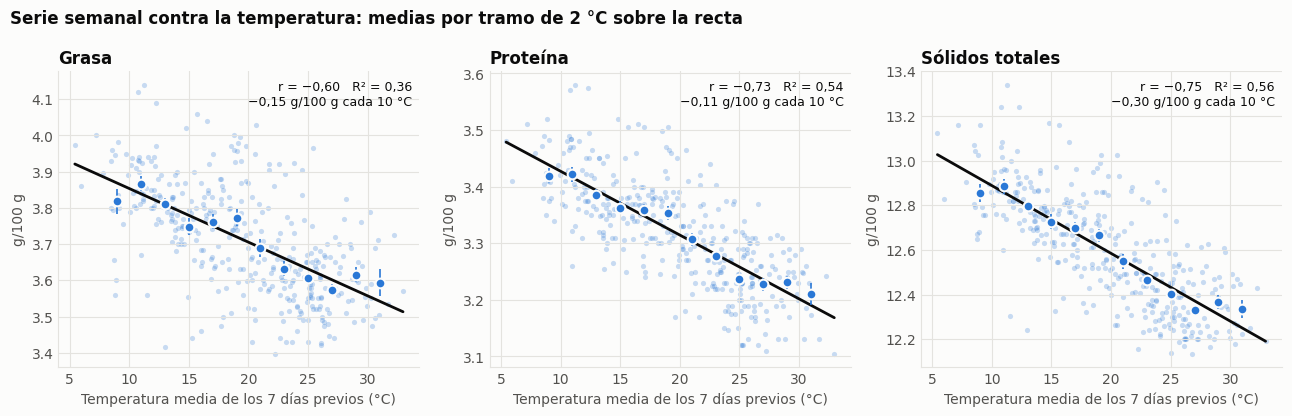

In [11]:
W = 7
fig, axes = plt.subplots(1, len(COMPONENTES), figsize=(13, 4.2))
tramos = np.arange(np.floor(sem[f"t{W}"].min() / 2) * 2, sem[f"t{W}"].max() + 2, 2)
for ax, p in zip(axes, COMPONENTES):
    nombre, unidad, _ = PARAMETROS[p]
    x, y = sem[f"t{W}"], sem[p]
    b, a = np.polyfit(x, y, 1)
    r = np.corrcoef(x, y)[0, 1]
    ax.scatter(x, y, s=14, color=AZUL, alpha=0.25, linewidths=0)
    xr = np.array([x.min(), x.max()])
    ax.plot(xr, a + b * xr, color=TEXTO, linewidth=2, solid_capstyle="round", zorder=3)
    medias = y.groupby(pd.cut(x, tramos), observed=True).agg(["mean", "sem", "size"]).query("size >= 5")
    centros = [iv.mid for iv in medias.index]
    ax.errorbar(centros, medias["mean"], yerr=medias["sem"], fmt="o", color=AZUL, markersize=7,
                markeredgecolor=SUPERFICIE, markeredgewidth=1.5, elinewidth=1.2, capsize=0, zorder=4)
    ax.set_title(nombre)
    ax.set_xlabel(f"Temperatura media de los {W} días previos (°C)")
    ax.set_ylabel(unidad)
    ax.text(0.98, 0.97, f"r = {dec(r, 2)}   R² = {dec(r ** 2, 2)}\n{dec(10 * b, 2)} g/100 g cada 10 °C",
            transform=ax.transAxes, ha="right", va="top", color=TEXTO, fontsize=9)
    ax.tick_params(axis="both", length=0)
fig.suptitle("Serie semanal contra la temperatura: medias por tramo de 2 °C sobre la recta",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
fig.savefig(GRAFICOS / "linealidad_semanal_temperatura.png", dpi=150)
plt.show()

### Más allá del calendario: anomalías y desfasaje

La temperatura acompaña a la estación, y con la estación cambian también la alimentación, el fotoperíodo
y el momento de lactancia de los rodeos. Para separar la temperatura del calendario se le resta a cada
serie semanal la media de su mes calendario (**anomalía**): si en las semanas más cálidas *de lo normal
para esa época* la leche viene más pobre *de lo normal para esa época*, hay un efecto de la temperatura
que el calendario no explica.

El **desfasaje** compara la composición de una semana con la temperatura de k semanas antes (k > 0) o
después (k < 0). Un componente que responde a la temperatura tiene su máximo |r| en k ≥ 0; si lo tiene
en k < 0 (la leche "se adelanta" a la temperatura), lo está moviendo otra cosa del ciclo anual.

In [12]:
sem_a = sem.copy()
mes = sem_a.index.month
for col in REFERENCIA + [f"t{W}"]:
    sem_a[col] = sem_a[col] - sem_a[col].groupby(mes).transform("mean")

filas = []
for p in REFERENCIA:
    r_crudo = sem[p].corr(sem[f"t{W}"])
    r_anom = sem_a[p].corr(sem_a[f"t{W}"])
    b_anom = np.polyfit(sem_a[f"t{W}"], sem_a[p], 1)[0]
    rezagos = {k: sem[p].corr(sem[f"t{W}"].shift(k)) for k in range(-12, 13)}
    k_mejor = min(rezagos, key=lambda k: rezagos[k])
    filas.append({"componente": p, "r_crudo": r_crudo, "r_anomalías": r_anom,
                  "pendiente_anom_10°C": 10 * b_anom, "semanas_mejor_desfasaje": k_mejor,
                  "r_mejor_desfasaje": rezagos[k_mejor]})
print(f"semanas: {len(sem)} | temperatura: media de los {W} días previos")
print(pd.DataFrame(filas).set_index("componente").round(3).to_string())

semanas: 366 | temperatura: media de los 7 días previos
                   r_crudo  r_anomalías  pendiente_anom_10°C  semanas_mejor_desfasaje  r_mejor_desfasaje
componente                                                                                              
grasa               -0.600       -0.270               -0.101                       -7             -0.717
proteina            -0.733       -0.475               -0.107                       -6             -0.735
solidos_totales     -0.749       -0.409               -0.244                        0             -0.749
solidos_no_grasos   -0.749       -0.390               -0.134                        0             -0.749
lactosa             -0.240       -0.078               -0.015                       11             -0.456


### Lectura

- **Es lineal en los tres.** El término cuadrático agrega como mucho 0,013 de R² (grasa), y en proteína
  y sólidos totales menos de 0,01; las medias por tramo de 2 °C caen sobre la recta. No hay umbral ni
  meseta en el rango de temperaturas de Rafaela. La relación es negativa en las diez industrias, en los
  tres componentes.
- **La linealidad aumenta al promediar, y lo hace en los tres.** Con la temperatura del día y la nube de
  industrias-día el r es moderado (grasa −0,37, proteína −0,49, sólidos −0,45) porque cada día suma ruido
  de muestreo. Con la media de los 7 días previos sube en los tres, y con la serie semanal llega a
  grasa −0,60, proteína −0,73 y sólidos −0,75 (R² 0,36 / 0,54 / 0,56). Ventanas de más de 15 días
  empeoran el ajuste: la respuesta es de días, no de meses.
- **Proteína y sólidos van juntos; la grasa acompaña, pero menos.** Los sólidos totales son lineales sobre
  todo por los **sólidos no grasos** (mismo r, −0,75), y la proteína es la que más se les parece. La grasa
  queda más baja y su mejor desfasaje es de −7 semanas (r −0,72 contra −0,60 sin desfasaje): pica en
  otoño, antes del frío, así que una parte de su ciclo la mueve otra cosa (fotoperíodo, lactancia,
  dieta). En proteína el desfasaje no distingue nada (−0,735 a −6 semanas contra −0,733 sin desfasaje),
  y en sólidos el mejor es 0.
- **El efecto sobrevive al calendario.** Descontada la media de cada mes, el r sigue negativo: proteína
  −0,48, sólidos −0,41, grasa −0,27. La lactosa casi no responde (−0,08).
- **Correlación no es causa**: esto muestra que la leche viene más pobre en las semanas más cálidas, también
  descontado el mes, no que el calor sea el único mecanismo.

## Correlación con la temperatura de la semana previa

Exploración: ¿la leche se parece más a la temperatura **de la semana anterior** que a la de la semana en que
se la analiza? Para cada fecha de análisis `d` se toma la temperatura media de los 7 días de `d−13` a `d−7`
(la semana inmediatamente anterior a la ventana de 7 días que termina en `d`), y como variante las medias de
15 y 30 días que terminan en `d−7`. Se compara con la misma ventana **sin desfase** (que termina en `d`).

- Misma serie diaria de temperatura, mismo agregado de la leche (mediana por industria-día y mediana semanal
  `W-MON` con al menos 3 industrias) y mismas funciones que arriba.
- Se compara en la **misma muestra** (las filas que tienen ambas temperaturas), a nivel industria-día y semana.
- **Anomalías**: se resta la media del mes calendario a la leche y a la temperatura (con y sin desfase). Si el
  desfase mejora el r solo en crudo y no en anomalías, la mejora viene de que el ciclo anual de la leche está
  corrido respecto del de la temperatura, no de una respuesta a la temperatura reciente.
- Convención: r es negativo (más calor, leche más pobre), así que **Δr = r con desfase − r sin desfase
  negativo significa que el desfase mejora la relación**.

In [13]:
LAG = 7                               # días de desfase: una semana
VENT_DESF = [1, 7, 15, 30]            # ventana principal: 7; variantes: 1, 15 y 30 días
NIVELES = [("industria-día", "ind"), ("semana", "sem")]

# temperatura sin desfase (termina en d, ya calculada como t{w}) y con desfase (termina en d - 7)
for w in VENT_DESF:
    if f"t{w}" not in corr:
        corr[f"t{w}"] = corr["fecha"].map(serie_t.rolling(f"{w}D").mean())
    corr[f"d{w}"] = (corr["fecha"] - pd.Timedelta(days=LAG)).map(serie_t.rolling(f"{w}D").mean())

# control: d7 de una fecha cualquiera es la media de los 7 días de d-13 a d-7
f0 = corr["fecha"].iloc[len(corr) // 2]
assert np.isclose(serie_t[f0 - pd.Timedelta(days=13): f0 - pd.Timedelta(days=7)].mean(),
                  corr.loc[corr["fecha"] == f0, "d7"].iloc[0])
print(f"ventana con desfase para {f0:%Y-%m-%d}: {f0 - pd.Timedelta(days=13):%Y-%m-%d} a {f0 - pd.Timedelta(days=7):%Y-%m-%d}")

agg = {**{p: "median" for p in REFERENCIA}, **{f"t{w}": "mean" for w in VENT_DESF}, **{f"d{w}": "mean" for w in VENT_DESF}}
sem_d = corr.groupby(g_sem).agg(agg)
sem_d = sem_d[corr.groupby(g_sem)["cliente"].nunique() >= MIN_INDUSTRIAS].dropna()
print(f"industrias-día: {len(corr):,} | semanas: {len(sem_d)} (la sección anterior: {len(sem)})")
assert sem_d.index.equals(sem.index)

tablas = {"ind": corr, "sem": sem_d}
meses = {"ind": corr["fecha"].dt.month, "sem": pd.Series(sem_d.index.month, index=sem_d.index)}


def estadisticos(x, y):
    b, a = np.polyfit(x, y, 1)
    return {"r": np.corrcoef(x, y)[0, 1], "pendiente": b, "R²_lin": r2(x, y, 1), "R²_cuad": r2(x, y, 2)}


filas = []
for nivel, k in NIVELES:
    tabla, mes = tablas[k], meses[k]
    for p in REFERENCIA:
        for w in VENT_DESF:
            d = tabla[[p, f"t{w}", f"d{w}"]].dropna()
            a = d - d.groupby(mes.loc[d.index].to_numpy()).transform("mean")
            fila = {"componente": p, "nivel": nivel, "ventana_días": w, "n": len(d)}
            for sufijo, col in [("sin", f"t{w}"), ("con", f"d{w}")]:
                for nombre_e, v in estadisticos(d[col].to_numpy(), d[p].to_numpy()).items():
                    fila[f"{nombre_e}_{sufijo}"] = v
                e_a = estadisticos(a[col].to_numpy(), a[p].to_numpy())
                fila[f"r_anom_{sufijo}"], fila[f"pend_anom_{sufijo}"] = e_a["r"], e_a["pendiente"]
            filas.append(fila)
desf = pd.DataFrame(filas)
desf["Δr"] = desf["r_con"] - desf["r_sin"]
desf["Δr_anom"] = desf["r_anom_con"] - desf["r_anom_sin"]

pd.set_option("display.width", 200)
ppal = desf[desf["ventana_días"] == 7]
for nivel, _ in NIVELES:
    print(f"--- ventana de 7 días · nivel {nivel} · n = {ppal[ppal.nivel == nivel]['n'].iloc[0]:,}")
    t_ = ppal[ppal.nivel == nivel].set_index("componente").loc[REFERENCIA]
    print(t_[["r_sin", "r_con", "Δr", "pendiente_sin", "pendiente_con", "R²_lin_sin", "R²_lin_con",
              "R²_cuad_sin", "R²_cuad_con"]].round(4).to_string())
    print(t_[["r_anom_sin", "r_anom_con", "Δr_anom", "pend_anom_sin", "pend_anom_con"]].round(4).to_string())
    print()
print("--- variantes de ventana: r sin desfase / con desfase (crudo y anomalías)")
for nivel, _ in NIVELES:
    v = desf[(desf.nivel == nivel) & desf["componente"].isin(COMPONENTES)]
    print(f"nivel {nivel}")
    print(v.pivot(index="componente", columns="ventana_días", values=["r_sin", "r_con", "r_anom_sin", "r_anom_con"])
          .round(3).to_string())
    print()

ventana con desfase para 2021-03-03: 2021-02-18 a 2021-02-24
industrias-día: 9,436 | semanas: 366 (la sección anterior: 366)


--- ventana de 7 días · nivel industria-día · n = 7,818
                    r_sin   r_con      Δr  pendiente_sin  pendiente_con  R²_lin_sin  R²_lin_con  R²_cuad_sin  R²_cuad_con
componente                                                                                                               
grasa             -0.3892 -0.3297  0.0595        -0.0146        -0.0123      0.1515      0.1087       0.1519       0.1088
proteina          -0.5824 -0.5028  0.0796        -0.0114        -0.0098      0.3392      0.2529       0.3393       0.2529
solidos_totales   -0.4979 -0.4388  0.0591        -0.0299        -0.0262      0.2479      0.1925       0.2484       0.1925
solidos_no_grasos -0.4840 -0.4417  0.0423        -0.0155        -0.0141      0.2343      0.1951       0.2344       0.1952
lactosa           -0.1377 -0.1558 -0.0181        -0.0025        -0.0028      0.0190      0.0243       0.0195       0.0244
                   r_anom_sin  r_anom_con  Δr_anom  pend_anom_sin  pend_anom_con
component

In [14]:
# ¿el desfase agrega información sobre la temperatura de la propia semana? Semanal, en anomalías:
# R² con la temperatura de la semana sola, con la desfasada sola y con ambas
def r2_multiple(X, y):
    X1 = np.column_stack([np.ones(len(X)), X])
    coef, *_ = np.linalg.lstsq(X1, y, rcond=None)
    return 1 - ((y - X1 @ coef) ** 2).sum() / ((y - y.mean()) ** 2).sum()


filas = []
for p in COMPONENTES + ["solidos_no_grasos", "lactosa"]:
    d = sem_d[[p, "t7", "d7"]]
    a = d - d.groupby(meses["sem"].to_numpy()).transform("mean")
    filas.append({"componente": p,
                  "R²_t7_sola": r2_multiple(a[["t7"]].to_numpy(), a[p].to_numpy()),
                  "R²_desfase_sola": r2_multiple(a[["d7"]].to_numpy(), a[p].to_numpy()),
                  "R²_ambas": r2_multiple(a[["t7", "d7"]].to_numpy(), a[p].to_numpy()),
                  "r_t7_vs_d7_anom": a["t7"].corr(a["d7"])})
print("--- semana, anomalías: R² con la temperatura de la semana, con la desfasada y con ambas")
print(pd.DataFrame(filas).set_index("componente").round(4).to_string())

# curva de r contra el desfase (en semanas, por calendario) con la misma serie semanal: crudo y anomalías
ks = list(range(-12, 13))
completa = sem_d.reindex(pd.date_range(sem_d.index.min(), sem_d.index.max(), freq="7D"))
curvas = {}
for p in COMPONENTES + ["solidos_no_grasos", "lactosa"]:
    cr, an = [], []
    for k in ks:
        d = pd.DataFrame({"y": completa[p], "x": completa["t7"].shift(k)}).dropna()
        cr.append(d["y"].corr(d["x"]))
        a = d - d.groupby(d.index.month).transform("mean")
        an.append(a["y"].corr(a["x"]))
    curvas[p] = pd.DataFrame({"crudo": cr, "anomalías": an}, index=ks)
res = []
for p, cv in curvas.items():
    res.append({"componente": p, "r_k0": cv.loc[0, "crudo"], "r_k1": cv.loc[1, "crudo"],
                "k_óptimo": cv["crudo"].idxmin(), "r_óptimo": cv["crudo"].min(),
                "anom_k0": cv.loc[0, "anomalías"], "anom_k1": cv.loc[1, "anomalías"],
                "k_óptimo_anom": cv["anomalías"].idxmin(), "r_óptimo_anom": cv["anomalías"].min()})
print()
print("--- rezago en semanas (k > 0: temperatura de k semanas antes), semana, ventana de 7 días")
print(pd.DataFrame(res).set_index("componente").round(3).to_string())

--- semana, anomalías: R² con la temperatura de la semana, con la desfasada y con ambas
                   R²_t7_sola  R²_desfase_sola  R²_ambas  r_t7_vs_d7_anom
componente                                                               
grasa                  0.0732           0.0341    0.0783           0.4459
proteina               0.2261           0.1011    0.2401           0.4459
solidos_totales        0.1672           0.0706    0.1759           0.4459
solidos_no_grasos      0.1520           0.0685    0.1617           0.4459
lactosa                0.0061           0.0002    0.0066           0.4459



--- rezago en semanas (k > 0: temperatura de k semanas antes), semana, ventana de 7 días
                    r_k0   r_k1  k_óptimo  r_óptimo  anom_k0  anom_k1  k_óptimo_anom  r_óptimo_anom
componente                                                                                         
grasa             -0.600 -0.521        -7    -0.717   -0.270   -0.191              0         -0.270
proteina          -0.733 -0.646        -6    -0.735   -0.475   -0.333              0         -0.475
solidos_totales   -0.749 -0.672         0    -0.749   -0.409   -0.270              0         -0.409
solidos_no_grasos -0.749 -0.697         0    -0.749   -0.390   -0.261              0         -0.390
lactosa           -0.240 -0.269        11    -0.456   -0.078   -0.006              0         -0.078


### Dispersión con la temperatura desfasada una semana

Los mismos gráficos de dispersión de arriba (cada punto es una industria-día, recta por mínimos cuadrados y
r por industria), pero el eje x es la **temperatura media del día una semana antes del análisis** (`d − 7`)
en lugar de la del mismo día. Abajo de cada gráfico se imprime el r sin desfase para comparar.

Grasa: grasa = 3.932 -0.0110 · temperatura (-0.11 g/100 g cada 10 °C) | r = -0.319 | R² = 0.102 | n = 7,818


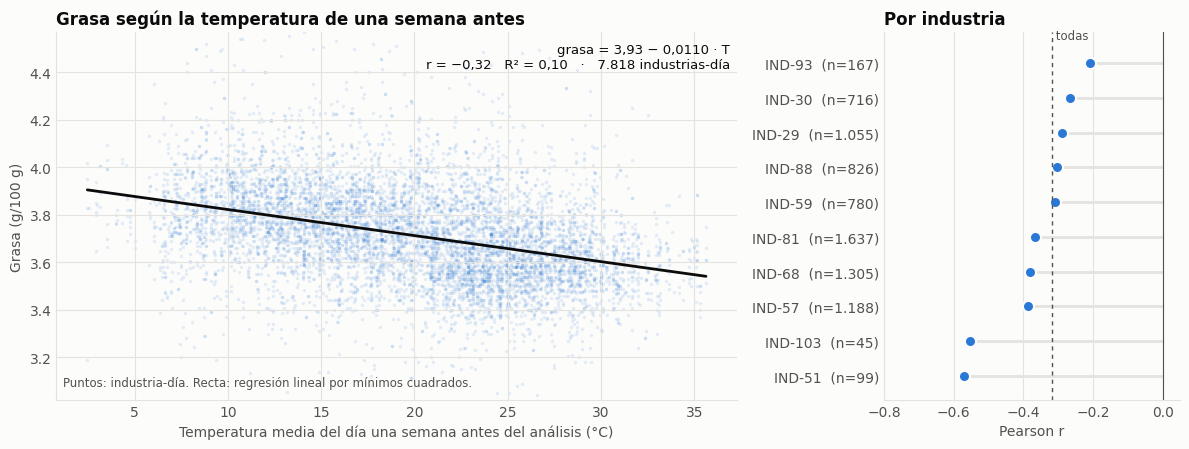

   sin desfase (temperatura del mismo día): r = -0.368

Proteína: proteína = 3.496 -0.0090 · temperatura (-0.09 g/100 g cada 10 °C) | r = -0.505 | R² = 0.255 | n = 7,821


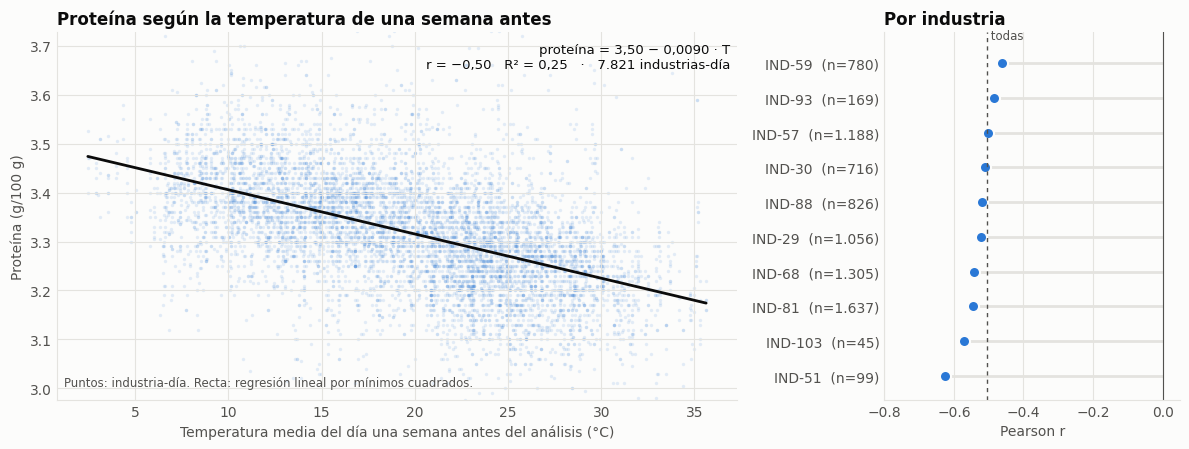

   sin desfase (temperatura del mismo día): r = -0.494

Sólidos totales: sólidos totales = 13.069 -0.0234 · temperatura (-0.23 g/100 g cada 10 °C) | r = -0.424 | R² = 0.180 | n = 7,822


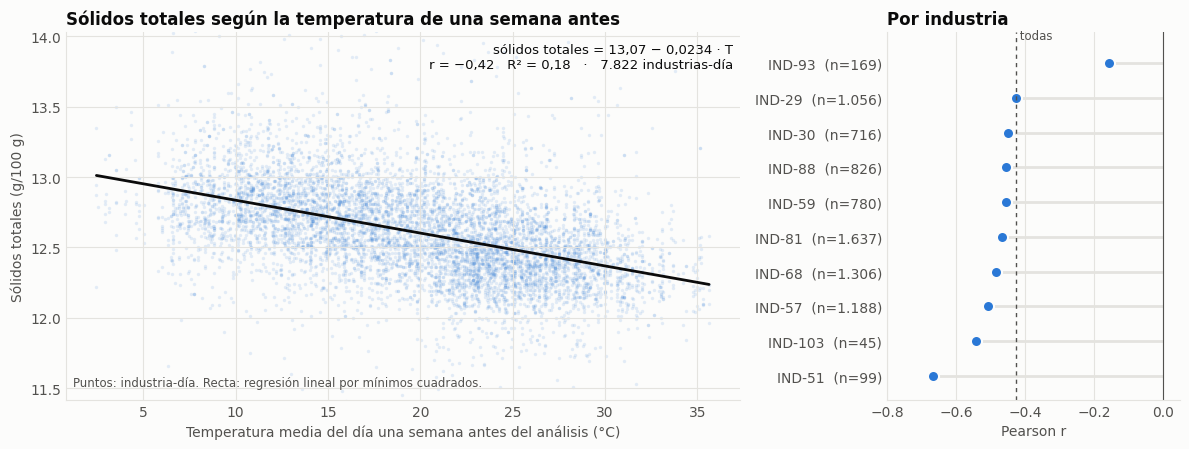

   sin desfase (temperatura del mismo día): r = -0.445

r por industria con desfase de una semana (entre paréntesis, sin desfase):
                   grasa         proteina  solidos_totales
cliente                                                   
IND-103  -0.552 (-0.611)  -0.571 (-0.678)  -0.541 (-0.619)
IND-29   -0.288 (-0.344)  -0.523 (-0.499)  -0.425 (-0.438)
IND-30   -0.266 (-0.335)  -0.511 (-0.496)    -0.45 (-0.49)
IND-51   -0.572 (-0.626)  -0.624 (-0.549)  -0.666 (-0.683)
IND-57   -0.387 (-0.445)  -0.501 (-0.508)  -0.508 (-0.526)
IND-59    -0.309 (-0.33)  -0.462 (-0.459)  -0.454 (-0.456)
IND-68    -0.38 (-0.414)  -0.542 (-0.517)  -0.483 (-0.487)
IND-81   -0.365 (-0.439)  -0.545 (-0.558)  -0.465 (-0.506)
IND-88    -0.302 (-0.34)  -0.519 (-0.468)  -0.453 (-0.458)
IND-93   -0.208 (-0.193)  -0.486 (-0.378)  -0.155 (-0.212)


In [15]:
corr["t_media_7d_antes"] = (corr["fecha"] - pd.Timedelta(days=LAG)).map(serie_t)
f0 = corr["fecha"].iloc[len(corr) // 2]
assert np.isclose(corr.loc[corr["fecha"] == f0, "t_media_7d_antes"].iloc[0], serie_t[f0 - pd.Timedelta(days=LAG)])

por_industria_desf = {}
for p in COMPONENTES:
    por_industria_desf[p] = figura_correlacion(
        p, x="t_media_7d_antes", eje_x="Temperatura media del día una semana antes del análisis (°C)",
        titulo="según la temperatura de una semana antes",
        archivo=f"correlacion_{p}_temperatura_desfase_1semana.png")
    _, _, r0, _ = recta(corr, p)
    print(f"   sin desfase (temperatura del mismo día): r = {r0:.3f}\n")
print("r por industria con desfase de una semana (entre paréntesis, sin desfase):")
print(pd.DataFrame({p: por_industria_desf[p]["r"].round(3).astype(str) + " ("
                       + por_industria[p]["r"].reindex(por_industria_desf[p].index).round(3).astype(str) + ")"
                    for p in COMPONENTES}).to_string())

### Lectura del desfase

Ventana de 7 días; r de Pearson sin desfase → con desfase de una semana. Industria-día: 7.818 filas; semana: 366.

| Componente | Industria-día, crudo | Industria-día, anomalías | Semana, crudo | Semana, anomalías |
|---|---|---|---|---|
| Grasa | −0,389 → −0,330 (Δr +0,060) | −0,129 → −0,062 (+0,066) | −0,600 → −0,517 (+0,083) | −0,271 → −0,185 (+0,086) |
| Proteína | −0,582 → −0,503 (+0,080) | −0,289 → −0,157 (+0,132) | −0,733 → −0,642 (+0,091) | −0,476 → −0,318 (+0,158) |
| Sólidos totales | −0,498 → −0,439 (+0,059) | −0,190 → −0,100 (+0,091) | −0,749 → −0,667 (+0,081) | −0,409 → −0,266 (+0,143) |

- **Dispersión con la temperatura del día una semana antes** (industria-día, gráficos de arriba): grasa
  r = −0,32 (sin desfase −0,37), proteína −0,50 (−0,49) y sólidos totales −0,42 (−0,45). La nube y la recta
  se ven casi iguales que sin desfase, porque la temperatura de un día y la de una semana después están muy
  correlacionadas. Proteína es la única que mejora apenas, y solo con un día aislado (ver «Variantes de
  ventana»): con la media de 7 días hasta el análisis el r sigue siendo mejor (−0,58).
- **El desfase no mejora la relación lineal: la empeora, en los tres componentes y en los cuatro cortes.** Δr
  es positivo en todas las celdas (el r se acerca a cero). A nivel semanal el R² lineal baja de 0,360 a
  0,267 en grasa, de 0,538 a 0,412 en proteína y de 0,560 a 0,445 en sólidos totales; la pendiente se achica
  (proteína −0,0113 → −0,0099 g/100 g por °C; grasa −0,0148 → −0,0128; sólidos −0,0304 → −0,0271). La
  relación sigue siendo lineal con el desfase: el término cuadrático suma menos de 0,002 de R².
- **Lo que se pierde está en la parte que no es calendario.** En crudo el desfase conserva alrededor del
  85-90% del r (proteína semanal −0,733 → −0,642), porque el ciclo anual es lento y una semana lo mueve poco.
  En anomalías conserva solo 65-68% (proteína −0,476 → −0,318; sólidos −0,409 → −0,266; grasa −0,271
  → −0,185). O sea: lo que sobrevive al desfase es sobre todo el ciclo estacional compartido, y la
  respuesta a la temperatura reciente, la que queda al descontar el mes, está en la **misma semana**.
- **El desfase no agrega información sobre la temperatura de la propia semana.** En anomalías semanales, el
  R² de la proteína es 0,226 con la temperatura de la semana, 0,101 con la desfasada y 0,240 con las dos
  (grasa 0,073 / 0,034 / 0,078; sólidos 0,167 / 0,071 / 0,176): sumar la desfasada aporta como mucho 0,014.
- **Variantes de ventana.** Con 15 y 30 días terminando en `d−7` el r también baja respecto de terminar en `d`
  (proteína semanal en crudo −0,700 → −0,604 con 15 días y −0,612 → −0,515 con 30; industria-día
  −0,557 → −0,479 y −0,490 → −0,413). La única mejora aparece con **un solo día** de temperatura: en proteína a
  nivel industria-día el día `d−7` rinde igual que el día `d` (−0,505 contra −0,494; en anomalías −0,174
  contra −0,085), y en anomalías semanales también (−0,381 contra −0,252). No es un efecto real del
  desfase: un día aislado es una medida ruidosa de la temperatura reciente y el día `d−7` se parece a
  la media de 7 días; en ninguna ventana supera a la media de 7 días hasta `d` (proteína −0,582, semanal
  −0,733).
- **El rezago óptimo coincide con la sección anterior.** Con la serie semanal por calendario, el r en crudo
  pasa de −0,600 (k = 0) a −0,521 (k = 1) en grasa, de −0,733 a −0,646 en proteína y de −0,749 a −0,672 en
  sólidos. El mejor rezago es k = 0 en sólidos y anomalías de todos los componentes, y en crudo k = −6 en
  proteína (−0,735, lo mismo que sin desfase) y k = −7 en grasa (−0,717): la leche se adelanta a la
  temperatura, señal de ciclo anual y no de respuesta. En los tres componentes, ningún k > 0 es el mejor.
- **Lactosa (referencia).** Es la única donde el desfase sube un poco el r en crudo (semanal −0,240 → −0,271), con
  un r muy bajo y en anomalías casi nulo (−0,078 → −0,014): no hay nada que explicar con la temperatura.

**Conclusión.** Usar la temperatura de la semana previa no mejora la correlación: la empeora en todos los cortes, y
la caída es mayor en anomalías que en crudo. La leche responde a la temperatura de los últimos días, no a la de
la semana anterior; lo que el desfase conserva es el ciclo estacional compartido. Para modelar, la ventana de
7 días que termina en la fecha del análisis es mejor que la de la semana previa. Correlación no es causa, y
estas conclusiones valen para esta serie (diez industrias, desde septiembre de 2019).

## Células somáticas (RCS) y recuento bacteriano (RBT) contra la temperatura

Los mismos gráficos de dispersión que para grasa, proteína y sólidos, ahora para los dos recuentos de calidad:

- **Cada punto es una industria-día** (mediana de la industria en el día) contra la temperatura media de ese día.
- **Escala logarítmica**: los recuentos son muy asimétricos (unos pocos días con valores diez veces más altos). La
  recta y el r se calculan sobre log₁₀ del recuento, así que la pendiente se lee como un **factor**: «×1,2 cada
  10 °C» quiere decir un 20 % más.
- **Línea naranja**: el umbral que usa la regresión logística de la Parte IV (400 000 células/mL y 100 000 UFC/mL;
  los datos están en miles por mL).
- El RBT de IND-59 desde mayo de 2024 no entra (otra unidad, ver la primera celda).
- Debajo, la misma prueba de **anomalías** de la sección de linealidad: serie semanal (mediana entre industrias-día,
  al menos 3 industrias) contra la temperatura media de los 7 días previos, en crudo y restando a las dos la media
  de su mes calendario. Si el r se va a cero en anomalías, lo que se ve en la nube es la estación, no el calor.

Células somáticas: log10 = 2.530 +0.0045 · temperatura (×1.11 cada 10 °C, +11 %) | r = 0.231 | R² = 0.053 | n = 7,809


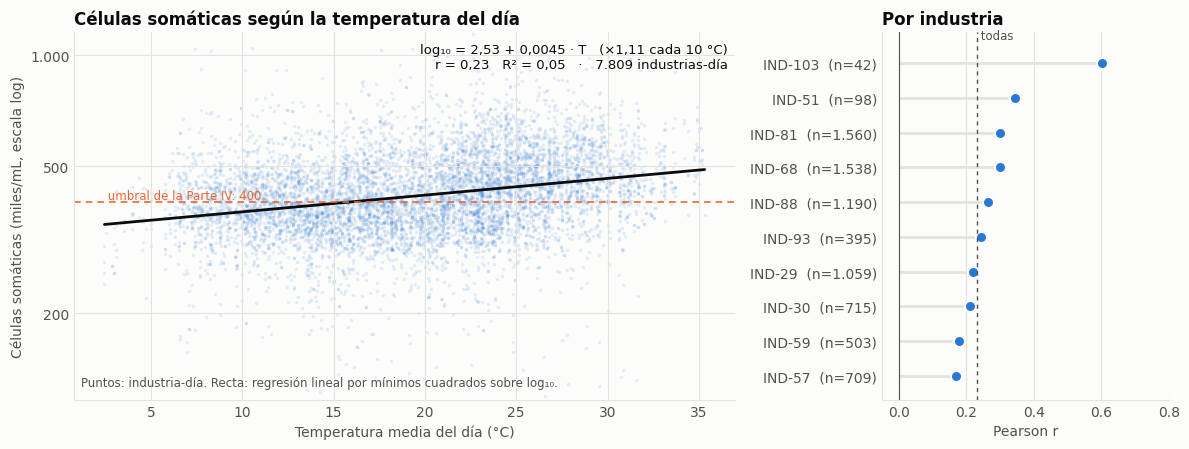

Recuento bacteriano total: log10 = 1.659 +0.0053 · temperatura (×1.13 cada 10 °C, +13 %) | r = 0.110 | R² = 0.012 | n = 8,308


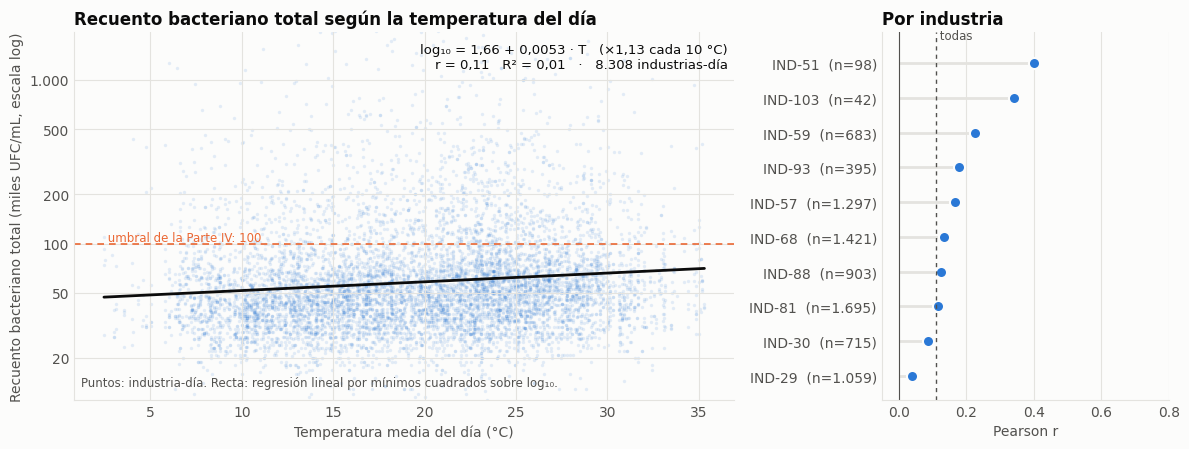


r por industria (sobre log10):
         celulas_somaticas    rbt
cliente                          
IND-103              0.602  0.342
IND-29               0.219  0.038
IND-30               0.210  0.087
IND-51               0.345  0.400
IND-57               0.168  0.166
IND-59               0.177  0.226
IND-68               0.300  0.133
IND-81               0.300  0.117
IND-88               0.263  0.124
IND-93               0.245  0.179

--- serie semanal contra la temperatura media de los 7 días previos (log10 del recuento)
                   semanas  r_crudo  factor_10°C_crudo  r_anomalías  factor_10°C_anomalías
recuento                                                                                  
celulas_somaticas      366    0.511              1.155        0.021                  1.008
rbt                    366    0.391              1.180        0.109                  1.106


In [16]:
UMBRALES = {"celulas_somaticas": L.UMBRAL_RCS, "rbt": L.UMBRAL_RBT}      # en miles por mL, como los datos
por_industria_rec = {}
for p in RECUENTOS:
    por_industria_rec[p] = figura_correlacion(p, umbral=UMBRALES[p])
print()
print("r por industria (sobre log10):")
print(pd.DataFrame({p: por_industria_rec[p]["r"] for p in RECUENTOS}).round(3).to_string())

# semanal, crudo y anomalías (como en «Más allá del calendario»)
logs = [f"log10_{p}" for p in RECUENTOS]
sem_rec = corr.groupby(g_sem).agg({**{c_: "median" for c_ in logs}, f"t{W}": "mean"})
sem_rec = sem_rec[corr.groupby(g_sem)["cliente"].nunique() >= MIN_INDUSTRIAS]
filas = []
for p, c_ in zip(RECUENTOS, logs):
    d = sem_rec[[c_, f"t{W}"]].dropna()
    a_ = d - d.groupby(d.index.month).transform("mean")
    b_crudo = np.polyfit(d[f"t{W}"], d[c_], 1)[0]
    b_anom = np.polyfit(a_[f"t{W}"], a_[c_], 1)[0]
    filas.append({"recuento": p, "semanas": len(d), "r_crudo": d[c_].corr(d[f"t{W}"]),
                  "factor_10°C_crudo": 10 ** (10 * b_crudo), "r_anomalías": a_[c_].corr(a_[f"t{W}"]),
                  "factor_10°C_anomalías": 10 ** (10 * b_anom)})
print()
print(f"--- serie semanal contra la temperatura media de los {W} días previos (log10 del recuento)")
print(pd.DataFrame(filas).set_index("recuento").round(3).to_string())

### Lectura de los recuentos

- **Los dos recuentos suben con el calor, al revés que la composición, pero la nube diaria casi no lo muestra.**
  Células somáticas: r = 0,23 (R² 0,05), ×1,11 cada 10 °C (un 11 % más). Recuento bacteriano: r = 0,11 (R² 0,01),
  ×1,13 cada 10 °C. La relación es positiva en las diez industrias, en los dos recuentos (de 0,17 a 0,60 en RCS y de
  0,04 a 0,40 en RBT; los r más altos son de las industrias con menos días, IND-103 e IND-51).
- **La mayoría de los días están lejos del umbral.** La recta de RCS cruza los 400 000 cél/mL alrededor de los
  16 °C. Ese corte está en el medio de la nube, y por eso la Parte IV lo puede modelar. El RBT queda casi entero
  por debajo de 100 000 UFC/mL, a cualquier temperatura, y por eso la Parte IV tiene tan pocos positivos ahí.
- **Lo que se ve es la estación, no el calor.** Con la serie semanal, el r de células somáticas sube a 0,51, y
  restando la media de cada mes cae a 0,02 (×1,01 cada 10 °C): el verano trae más células, pero una semana más
  caliente de lo normal para la fecha no trae más células de lo normal. Es lo mismo que encuentra la regresión
  logística (Parte IV): con la fecha en el modelo, el odds ratio por grado de anomalía es 0,99.
- **En el recuento bacteriano queda una señal chica**: r 0,39 en crudo y 0,11 en anomalías (×1,11 cada 10 °C).
  Con 366 semanas el error típico de r ronda 0,05, y las semanas seguidas no son independientes, así que está
  apenas en el borde de lo distinguible de cero. Es coherente con que el calor favorezca el crecimiento de
  bacterias entre el ordeñe y el enfriado, pero no alcanza para afirmarlo.
- **Correlación no es causa**, igual que arriba.

## Datos usados en cada entrenamiento

Una fila por cada ajuste, con las mismas columnas que en las otras partes. Son rectas por mínimos cuadrados (por
industria-día y por semana) que describen la asociación con todos los datos: no hay partición y ninguna se usa para
predecir casos nuevos.

In [17]:
def miles(n):
    return f"{int(n):,}".replace(",", ".")

SIN_PART = "sin partición: describe la asociación con todos los datos"
NOMBRES = {"grasa": "grasa", "proteina": "proteína", "solidos_totales": "sólidos totales",
           "celulas_somaticas": "log10 de células somáticas", "rbt": "log10 del recuento bacteriano"}
n_dia = len(dia)
filas = []
for p in COMPONENTES + RECUENTOS:
    col = f"log10_{p}" if p in RECUENTOS else p
    n = int(corr[[col, "t_media"]].notna().all(axis=1).sum())
    filas.append(DE.fila("VIII", f"recta por mínimos cuadrados: {NOMBRES[p]} ~ temperatura del día", "industrias-día desde septiembre de 2019 "
                         "(mediana de cada industria en el día)", n_dia, n,
                         motivo=f"sin {NOMBRES[p]} ese día o sin temperatura: {miles(n_dia - n)}", particion=SIN_PART,
                         nota="también por industria y con la temperatura de una semana antes" if p in COMPONENTES else "también por industria"))
n_sem_tot = int(corr.groupby(g_sem).ngroups)
filas.append(DE.fila("VIII", "serie semanal: recta y parábola contra la temperatura de 1 a 90 días (5 componentes)",
                     "semanas (mediana entre industrias-día)", n_sem_tot, len(sem),
                     motivo=f"semanas con menos de {MIN_INDUSTRIAS} industrias o sin algún componente: {miles(n_sem_tot - len(sem))}",
                     particion=SIN_PART, nota="las mismas semanas sirven para las anomalías mensuales y el desfase de una semana"))
with pd.option_context("display.max_colwidth", 120):
    display(DE.guardar(filas, "temperatura_leche_cruda"))

,parte,modelo,datos,disponibles,excluidas,motivo de exclusión,usadas,entrenamiento,validación,prueba,partición,nota
0,VIII,recta por mínimos cuadrados: grasa ~ temperatura del día,industrias-día desde septiembre de 2019 (mediana de cada industria en el día),9436,1618,sin grasa ese día o sin temperatura: 1.618,7818,7818,<NA>,<NA>,sin partición: describe la asociación con todos los datos,también por industria y con la temperatura de una semana antes
1,VIII,recta por mínimos cuadrados: proteína ~ temperatura del día,industrias-día desde septiembre de 2019 (mediana de cada industria en el día),9436,1615,sin proteína ese día o sin temperatura: 1.615,7821,7821,<NA>,<NA>,sin partición: describe la asociación con todos los datos,también por industria y con la temperatura de una semana antes
2,VIII,recta por mínimos cuadrados: sólidos totales ~ temperatura del día,industrias-día desde septiembre de 2019 (mediana de cada industria en el día),9436,1614,sin sólidos totales ese día o sin temperatura: 1.614,7822,7822,<NA>,<NA>,sin partición: describe la asociación con todos los datos,también por industria y con la temperatura de una semana antes
3,VIII,recta por mínimos cuadrados: log10 de células somáticas ~ temperatura del día,industrias-día desde septiembre de 2019 (mediana de cada industria en el día),9436,1627,sin log10 de células somáticas ese día o sin temperatura: 1.627,7809,7809,<NA>,<NA>,sin partición: describe la asociación con todos los datos,también por industria
4,VIII,recta por mínimos cuadrados: log10 del recuento bacteriano ~ temperatura del día,industrias-día desde septiembre de 2019 (mediana de cada industria en el día),9436,1128,sin log10 del recuento bacteriano ese día o sin temperatura: 1.128,8308,8308,<NA>,<NA>,sin partición: describe la asociación con todos los datos,también por industria
5,VIII,serie semanal: recta y parábola contra la temperatura de 1 a 90 días (5 componentes),semanas (mediana entre industrias-día),367,1,semanas con menos de 3 industrias o sin algún componente: 1,366,366,<NA>,<NA>,sin partición: describe la asociación con todos los datos,las mismas semanas sirven para las anomalías mensuales y el desfase de una semana


## Conclusiones de la parte

**Composición: con más calor, la leche es más pobre.**
- Por industria-día, r de −0,37 en grasa, −0,49 en proteína y −0,45 en sólidos totales, con el mismo signo en las
  diez industrias.
- La relación es lineal: el término cuadrático agrega como mucho 0,013 de R².
- Por semana, con la temperatura media de los 7 días previos, llega a −0,60 / −0,73 / −0,75.
- Restando el calendario se mantiene en parte (−0,27 / −0,48 / −0,41), así que no es solo la estación.
- Usar la temperatura de la semana anterior no la mejora.

**Recuentos: lo que se ve es la estación.**
- En crudo, el RCS y el RBT suben con la temperatura: r 0,23 y 0,11 por industria-día, ×1,11 y ×1,13 cada 10 °C.
- En anomalías semanales, el RCS cae a 0,02. Coincide con la Parte IV.
- El RBT queda en 0,11, en el borde de lo distinguible de cero.

**Límites.**
- Todo es asociación con la temperatura de un solo punto, no causalidad.
- La parte describe; los modelos que predicen la leche cruda son los de las Partes III y IV.

In [18]:
assert "archivo" not in leche.columns
assert set(leche["cliente"].astype(str).str.match(r"^IND-\d+$")) == {True}
assert (DE.CARPETA / "temperatura_leche_cruda.csv").exists()
print(f"Verificación: todo en orden · la parte tardó {(time.time() - inicio) / 60:.1f} min".replace(".", ","))

Verificación: todo en orden · la parte tardó 0,2 min
